In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [13]:
# ==================================================
# STAGE 1: LOADING AND PREPROCESSING IMAGE DATA
# ==================================================

# 2B: Load MNIST dataset from CSV files
train_data = pd.read_csv('mnist_train.csv')
test_data = pd.read_csv('mnist_test.csv')


In [14]:
# Separate images and labels
x_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

x_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

# Convert labels into 0 to 23
classes = np.unique(y_train)
label_map = {label: i for i, label in enumerate(classes)}

y_train = np.array([label_map[label] for label in y_train])
y_test = np.array([label_map[label] for label in y_test])

# Reshape images into 28x28 grayscale images
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Normalize image pixel values between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [15]:
# ==================================================
# STAGE 2: DEFINING THE CNN MODEL ARCHITECTURE
# ==================================================

# MNIST has 10 classes
num_classes = 10

model = keras.Sequential([
    layers.Input(shape=x_train.shape[1:]),

    # First Convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Third Convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),

    # Fully Connected Layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Output Layer
    layers.Dense(num_classes, activation='softmax')
])

# Display model architecture
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)                    │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 7, 7, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 6272)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │         802,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 896,906 (3.42 MB)

 Trainable params: 896,906 (3.42 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# ==================================================
# STAGE 3: TRAINING THE CNN MODEL
# ==================================================

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 172s 168ms/step - accuracy: 0.9344 - loss: 0.2135 - val_accuracy: 0.9880 - val_loss: 0.0404
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 146s 173ms/step - accuracy: 0.9797 - loss: 0.0702 - val_accuracy: 0.9905 - val_loss: 0.0328
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 139s 164ms/step - accuracy: 0.9861 - loss: 0.0491 - val_accuracy: 0.9918 - val_loss: 0.0298
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 133s 157ms/step - accuracy: 0.9883 - loss: 0.0410 - val_accuracy: 0.9923 - val_loss: 0.0305
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 95s 101ms/step - accuracy: 0.9907 - loss: 0.0305 - val_accuracy: 0.9915 - val_loss: 0.0305
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 119s 141ms/step - accuracy: 0.9916 - loss: 0.0279 - val_accuracy: 0.9905 - val_loss: 0.0386
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 118s 139ms/step - accuracy: 0.9933 - loss: 0.0229 - val_accuracy: 0.9940 - val_loss: 0.0260
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 97s 114ms/step - accuracy: 0.9938 - l

In [6]:
# ==================================================
# STAGE 4: ESTIMATING MODEL PERFORMANCE
# ==================================================

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 40ms/step - accuracy: 0.9937 - loss: 0.0228
Test Loss: 0.022830555215477943
Test Accuracy: 99.37000274658203 %


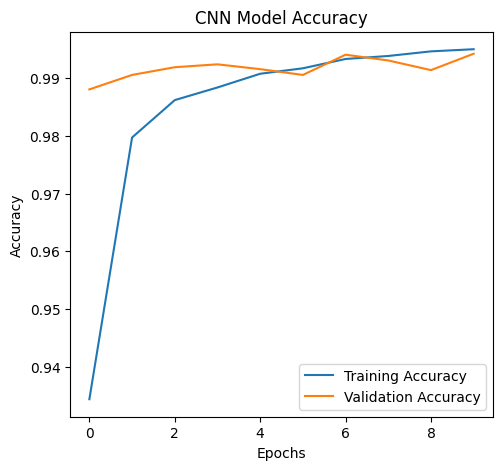

In [7]:
# Plot training and validation accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

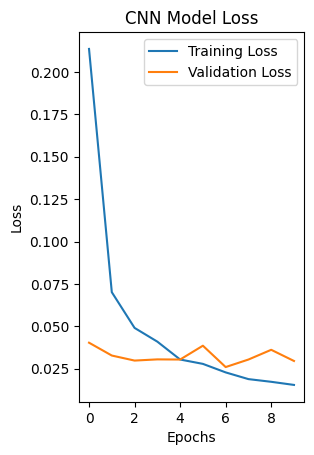

In [8]:
# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()